# BigBasket Product Data Analysis
## Project objective
Analyze the provided BigBasket product dataset to understand category distribution, brand representation, product ratings, selling prices, market prices, discounts, and price segments.

**Data source:** `bigbasket_sample - data.csv` (1,249 records, 10 columns).

**Scraping note:** The live BigBasket website returned HTTP 403 (Access Denied), so this project uses the supplied CSV dataset rather than claiming to scrape live data. Run cells from top to bottom.


## 1. Import libraries and locate the dataset

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving bigbasket_cleaned.csv to bigbasket_cleaned (4).csv


In [ ]:
import pandas as pd
import os

DATA_FILE = "/content/bigbasket_cleaned (1).csv"

df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Rows and columns: (1249, 11)
Columns: ['Item_ID', 'Product', 'Category', 'Subcategory', 'Brand', 'Price', 'MRP', 'Product_Type', 'Rating', 'Price_Segment', 'Discount']


,Item_ID,Product,Category,Subcategory,Brand,Price,MRP,Product_Type,Rating,Price_Segment,Discount
0,2,Water Bottle - Orange,Kitchen Garden & Pets,Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,Medium,0.000000
1,3,Brass Angle Deep - Plain No.2,Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,Medium,52.400000
2,4,Cereal Flip Lid Container/Storage Jar - Assorted Colour,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,Laundry Storage Baskets,3.7,Medium,15.340909
3,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Medium,0.000000
4,56,Soothing Cucumber Facial Scrub With Apricot Seeds,Beauty & Hygiene,Skin Care,TJORI,299.4,499.0,Face Care,NaN,Medium,40.000000


In [ ]:
# Create the raw dataset variable
df_raw = df.copy()

print("Column names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.to_frame("Data type"))

print("\nDataset shape:")
print(df_raw.shape)

display(df_raw.head())


Column names:
['Item_ID', 'Product', 'Category', 'Subcategory', 'Brand', 'Price', 'MRP', 'Product_Type', 'Rating', 'Price_Segment', 'Discount']

Data types:


,Data type
Item_ID,int64
Product,object
Category,object
Subcategory,object
Brand,object
Price,float64
MRP,float64
Product_Type,object
Rating,float64
Price_Segment,object



Dataset shape:
(1249, 11)


,Item_ID,Product,Category,Subcategory,Brand,Price,MRP,Product_Type,Rating,Price_Segment,Discount
0,2,Water Bottle - Orange,Kitchen Garden & Pets,Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,Medium,0.000000
1,3,Brass Angle Deep - Plain No.2,Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,Medium,52.400000
2,4,Cereal Flip Lid Container/Storage Jar - Assorted Colour,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,Laundry Storage Baskets,3.7,Medium,15.340909
3,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Medium,0.000000
4,56,Soothing Cucumber Facial Scrub With Apricot Seeds,Beauty & Hygiene,Skin Care,TJORI,299.4,499.0,Face Care,NaN,Medium,40.000000


## 2. Understand the dataset

In [ ]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.to_frame("Data type"))

print("\nDataset information:")
df_raw.info()

print("\nDescriptive statistics:")
display(df_raw.describe(include="all").T)


Column names:
['Item_ID', 'Product', 'Category', 'Subcategory', 'Brand', 'Price', 'MRP', 'Product_Type', 'Rating', 'Price_Segment', 'Discount']

Data types:


,Data type
Item_ID,int64
Product,object
Category,object
Subcategory,object
Brand,object
Price,float64
MRP,float64
Product_Type,object
Rating,float64
Price_Segment,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1249 entries, 0 to 1248
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Item_ID        1249 non-null   int64  
 1   Product        1249 non-null   object 
 2   Category       1249 non-null   object 
 3   Subcategory    1249 non-null   object 
 4   Brand          1249 non-null   object 
 5   Price          1249 non-null   float64
 6   MRP            1249 non-null   float64
 7   Product_Type   1249 non-null   object 
 8   Rating         855 non-null    float64
 9   Price_Segment  1249 non-null   object 
 10  Discount       1249 non-null   float64
dtypes: float64(4), int64(1), object(6)
memory usage: 107.5+ KB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item_ID,1249.0,NaN,NaN,NaN,7929.225781,5013.260283,2.0,3460.0,7634.0,11724.0,18452.0
Product,1249,1237,Chilli Powder/Menasina Pudi,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,1249,11,Beauty & Hygiene,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Subcategory,1249,83,Skin Care,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,1249,689,Fresho,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,1249.0,NaN,NaN,NaN,334.312666,504.200458,5.0,99.18,195.3,351.0,6700.0
MRP,1249.0,NaN,NaN,NaN,394.13534,608.634245,5.0,115.0,225.0,408.0,7875.0
Product_Type,1249,289,Face Care,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,855.0,NaN,NaN,NaN,3.93462,0.77126,1.0,3.7,4.1,4.3,5.0
Price_Segment,1249,3,Medium,742,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data cleaning and preparation

In [ ]:
# Rename source columns into readable, consistent names.
column_mapping = {
    "index_items": "Item_ID",
    "product_name": "Product",
    "category_name": "Category",
    "sub_category": "Subcategory",
    "brand_name": "Brand",
    "sale_price": "Price",
    "market_price": "MRP",
    "type_product": "Product_Type",
    "rating_product": "Rating",
    "price_segment": "Price_Segment",
}
df = df_raw.rename(columns=column_mapping).copy()

# Convert numeric columns safely.
for col in ["Item_ID", "Price", "MRP", "Rating"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Trim whitespace in text columns.
text_columns = ["Product", "Category", "Subcategory", "Brand", "Product_Type", "Price_Segment"]
for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Remove rows without a product name and exact duplicate records.
df = df.dropna(subset=["Product"])
df = df.drop_duplicates()

# Fill missing ratings with NaN retained: a missing rating means no rating was supplied.
# Fill missing descriptive labels with 'Unknown' so category counts remain usable.
for col in ["Category", "Subcategory", "Brand", "Product_Type", "Price_Segment"]:
    df[col] = df[col].fillna("Unknown").replace("", "Unknown")

# Treat negative prices as invalid missing values.
for col in ["Price", "MRP"]:
    df.loc[df[col] < 0, col] = np.nan

# Calculate discount percentage from market and sale price where possible.
valid_prices = df["MRP"].gt(0) & df["Price"].notna()
df["Discount"] = np.nan
df.loc[valid_prices, "Discount"] = (
    (df.loc[valid_prices, "MRP"] - df.loc[valid_prices, "Price"])
    / df.loc[valid_prices, "MRP"] * 100
).clip(0, 100)

print("Rows before cleaning:", len(df_raw))
print("Rows after cleaning:", len(df))
display(df.head())


Rows before cleaning: 1249
Rows after cleaning: 1249


,Item_ID,Product,Category,Subcategory,Brand,Price,MRP,Product_Type,Rating,Price_Segment,Discount
0,2,Water Bottle - Orange,Kitchen Garden & Pets,Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,Medium,0.000000
1,3,Brass Angle Deep - Plain No.2,Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,Medium,52.400000
2,4,Cereal Flip Lid Container/Storage Jar - Assorted Colour,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,Laundry Storage Baskets,3.7,Medium,15.340909
3,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Medium,0.000000
4,56,Soothing Cucumber Facial Scrub With Apricot Seeds,Beauty & Hygiene,Skin Care,TJORI,299.4,499.0,Face Care,NaN,Medium,40.000000


## 4. Missing values, duplicates, and validation

In [ ]:
missing_summary = df.isna().sum().to_frame("Missing values")
missing_summary["Missing (%)"] = (missing_summary["Missing values"] / len(df) * 100).round(2)
display(missing_summary)

print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Missing product names:", int(df["Product"].isna().sum()))
print("Invalid/non-positive sale prices:", int(df["Price"].le(0).sum()))
print("Invalid/non-positive market prices:", int(df["MRP"].le(0).sum()))
print("Ratings outside the 0-5 range:", int((~df["Rating"].between(0, 5) & df["Rating"].notna()).sum()))
print("Calculated discounts outside 0-100%:", int((~df["Discount"].between(0, 100) & df["Discount"].notna()).sum()))


,Missing values,Missing (%)
Item_ID,0,0.00
Product,0,0.00
Category,0,0.00
Subcategory,0,0.00
Brand,0,0.00
Price,0,0.00
MRP,0,0.00
Product_Type,0,0.00
Rating,394,31.55
Price_Segment,0,0.00


Exact duplicate rows: 0
Missing product names: 0
Invalid/non-positive sale prices: 0
Invalid/non-positive market prices: 0
Ratings outside the 0-5 range: 0
Calculated discounts outside 0-100%: 0


## 5. Outlier detection using the IQR method

In [ ]:
numeric_columns = ["Price", "MRP", "Rating", "Discount"]
outlier_rows = []

for col in numeric_columns:
    values = df[col].dropna()
    if values.empty:
        continue
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({
        "Column": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower bound": lower, "Upper bound": upper, "Outlier count": count
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))
print("Note: IQR flags unusual values for investigation; it does not automatically mean the values are wrong.")


,Column,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count
0,Price,99.18,351.0,251.82,-278.55,728.73,112
1,MRP,115.00,408.0,293.00,-324.50,847.50,113
2,Rating,3.70,4.3,0.60,2.80,5.20,65
3,Discount,0.00,20.0,20.00,-30.00,50.00,20


Note: IQR flags unusual values for investigation; it does not automatically mean the values are wrong.


## 6. Category, subcategory, and brand analysis

In [ ]:
print("Number of unique categories:", df["Category"].nunique())
print("Number of unique subcategories:", df["Subcategory"].nunique())
print("Number of unique brands:", df["Brand"].nunique())

print("\nProducts by category:")
display(df["Category"].value_counts().to_frame("Product count"))

print("\nTop 15 brands by number of listed products:")
display(df["Brand"].value_counts().head(15).to_frame("Product count"))

print("\nProducts by price segment:")
display(df["Price_Segment"].value_counts().to_frame("Product count"))


Number of unique categories: 11
Number of unique subcategories: 83
Number of unique brands: 689

Products by category:


,Product count
Category,
Beauty & Hygiene,394
Gourmet & World Food,202
Kitchen Garden & Pets,155
Foodgrains Oil & Masala,114
Cleaning & Household,113
Snacks & Branded Foods,111
Beverages,59
Bakery Cakes & Dairy,43
Baby Care,22



Top 15 brands by number of listed products:


,Product count
Brand,
Fresho,22
BB Home,13
bb Royal,13
DP,11
INATUR,10
Colgate,10
Kaya Clinic,8
Himalaya,8
Nakoda,7



Products by price segment:


,Product count
Price_Segment,
Medium,742
Low,315
High,192


## 7. Price and rating statistics

In [ ]:
summary = df[["Price", "MRP", "Discount", "Rating"]].describe().T
summary["median"] = df[["Price", "MRP", "Discount", "Rating"]].median()
display(summary.round(2))

print("Average sale price (₹):", round(df["Price"].mean(), 2))
print("Median sale price (₹):", round(df["Price"].median(), 2))
print("Average market price (₹):", round(df["MRP"].mean(), 2))
print("Average calculated discount (%):", round(df["Discount"].mean(), 2))
print("Average rating:", round(df["Rating"].mean(), 2))
print("Number of products with a rating:", int(df["Rating"].notna().sum()))


,count,mean,std,min,25%,50%,75%,max,median
Price,1249.0,334.31,504.20,5.0,99.18,195.3,351.0,6700.00,195.3
MRP,1249.0,394.14,608.63,5.0,115.00,225.0,408.0,7875.00,225.0
Discount,1249.0,11.10,14.42,0.0,0.00,5.0,20.0,79.24,5.0
Rating,855.0,3.93,0.77,1.0,3.70,4.1,4.3,5.00,4.1


Average sale price (₹): 334.31
Median sale price (₹): 195.3
Average market price (₹): 394.14
Average calculated discount (%): 11.1
Average rating: 3.93
Number of products with a rating: 855


## 8. Visualizations

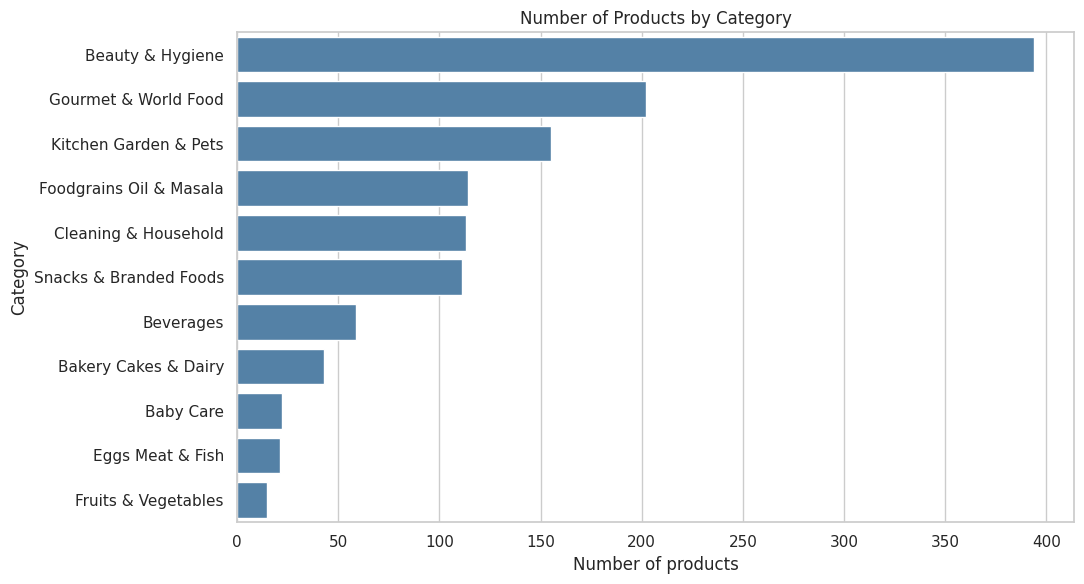

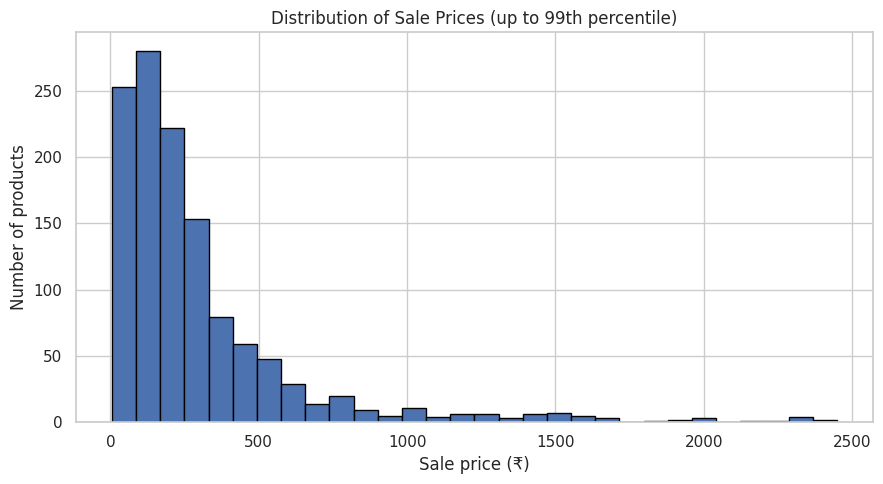

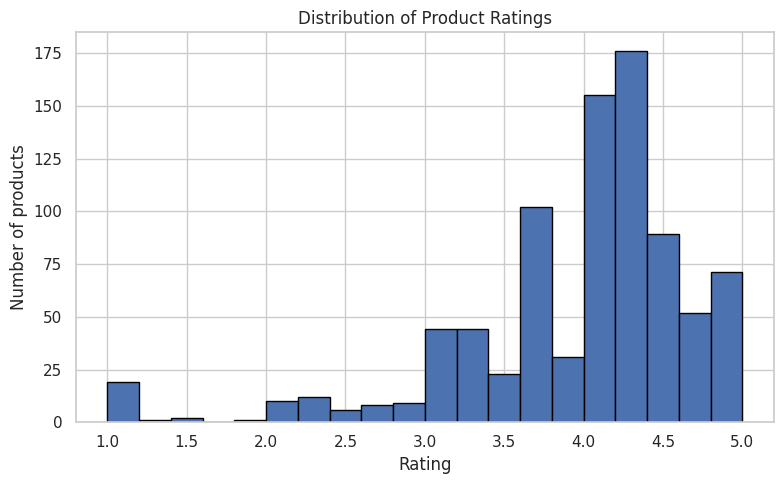

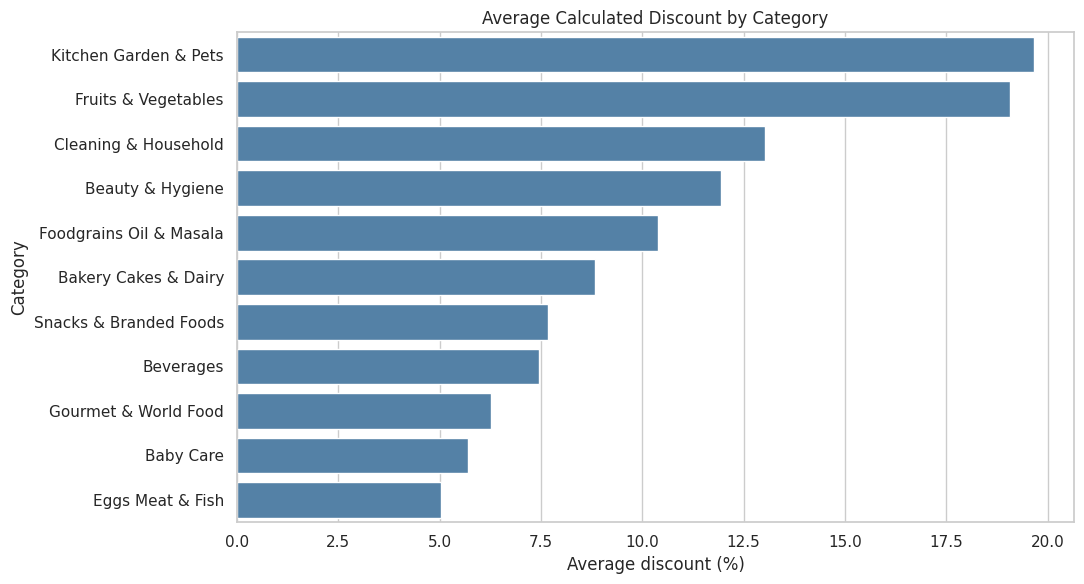

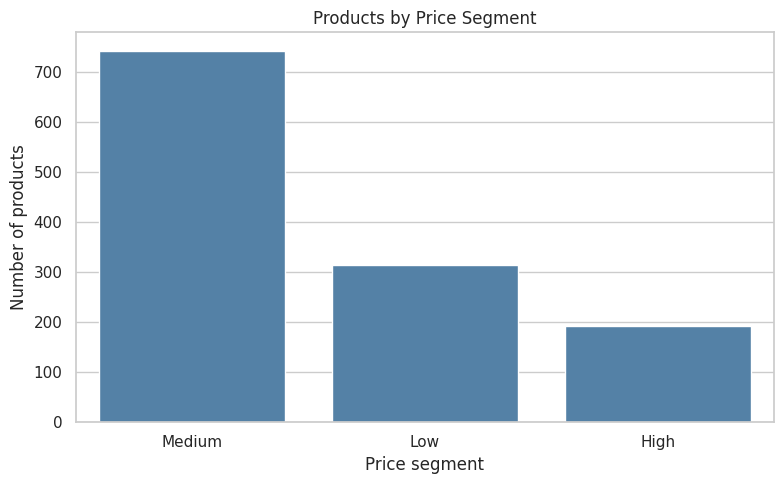

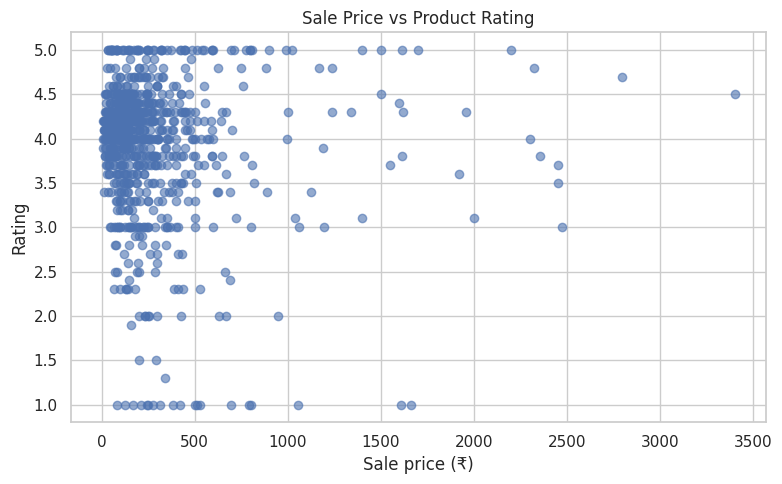

In [ ]:
# Chart 1: Product count by category
category_counts = df["Category"].value_counts()
plt.figure(figsize=(11, 6))
sns.barplot(x=category_counts.values, y=category_counts.index, color="steelblue")
plt.title("Number of Products by Category")
plt.xlabel("Number of products")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Chart 2: Sale price distribution (hide extreme display range using the 99th percentile)
price_values = df["Price"].dropna()
if not price_values.empty:
    upper_limit = price_values.quantile(0.99)
    plt.figure(figsize=(9, 5))
    plt.hist(price_values[price_values <= upper_limit], bins=30, edgecolor="black")
    plt.title("Distribution of Sale Prices (up to 99th percentile)")
    plt.xlabel("Sale price (₹)")
    plt.ylabel("Number of products")
    plt.tight_layout()
    plt.show()

# Chart 3: Product ratings
rating_values = df["Rating"].dropna()
if not rating_values.empty:
    plt.figure(figsize=(8, 5))
    plt.hist(rating_values, bins=20, edgecolor="black")
    plt.title("Distribution of Product Ratings")
    plt.xlabel("Rating")
    plt.ylabel("Number of products")
    plt.tight_layout()
    plt.show()

# Chart 4: Average discount by category
discount_by_category = (
    df.dropna(subset=["Discount"])
      .groupby("Category")["Discount"]
      .mean()
      .sort_values(ascending=False)
)
if not discount_by_category.empty:
    plt.figure(figsize=(11, 6))
    sns.barplot(x=discount_by_category.values, y=discount_by_category.index, color="steelblue")
    plt.title("Average Calculated Discount by Category")
    plt.xlabel("Average discount (%)")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

# Chart 5: Price segment distribution
segment_counts = df["Price_Segment"].value_counts()
plt.figure(figsize=(8, 5))
sns.barplot(x=segment_counts.index, y=segment_counts.values, color="steelblue")
plt.title("Products by Price Segment")
plt.xlabel("Price segment")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

# Chart 6: Sale price versus rating
rating_price = df.dropna(subset=["Price", "Rating"])
if not rating_price.empty:
    plt.figure(figsize=(8, 5))
    plt.scatter(rating_price["Price"], rating_price["Rating"], alpha=0.6)
    plt.title("Sale Price vs Product Rating")
    plt.xlabel("Sale price (₹)")
    plt.ylabel("Rating")
    plt.tight_layout()
    plt.show()


## 9. Category-wise comparison

In [ ]:
category_summary = (
    df.groupby("Category")
      .agg(
          Product_Count=("Product", "count"),
          Average_Sale_Price=("Price", "mean"),
          Average_Market_Price=("MRP", "mean"),
          Average_Discount=("Discount", "mean"),
          Average_Rating=("Rating", "mean"),
      )
      .sort_values("Product_Count", ascending=False)
)
display(category_summary.round(2))


,Product_Count,Average_Sale_Price,Average_Market_Price,Average_Discount,Average_Rating
Category,,,,,
Beauty & Hygiene,394,445.00,530.50,11.93,3.88
Gourmet & World Food,202,327.63,353.78,6.27,4.02
Kitchen Garden & Pets,155,531.74,682.24,19.67,3.75
Foodgrains Oil & Masala,114,161.32,189.12,10.39,4.12
Cleaning & Household,113,223.04,263.69,13.04,3.84
Snacks & Branded Foods,111,145.41,160.06,7.68,4.03
Beverages,59,232.38,254.07,7.44,3.98
Bakery Cakes & Dairy,43,120.22,130.88,8.83,3.98
Baby Care,22,419.91,459.95,5.71,4.32


## 10. Save cleaned data and analysis outputs

In [ ]:
cleaned_file = Path("bigbasket_cleaned.csv")
summary_file = Path("bigbasket_category_summary.csv")
outlier_file = Path("bigbasket_outlier_summary.csv")

df.to_csv(cleaned_file, index=False)
category_summary.to_csv(summary_file)
outlier_summary.to_csv(outlier_file, index=False)

print("Saved cleaned dataset:", cleaned_file.resolve())
print("Saved category summary:", summary_file.resolve())
print("Saved outlier summary:", outlier_file.resolve())


Saved cleaned dataset: /content/bigbasket_cleaned.csv
Saved category summary: /content/bigbasket_category_summary.csv
Saved outlier summary: /content/bigbasket_outlier_summary.csv


## 11. Sale price prediction using Gradient Boosting

We will train a `GradientBoostingRegressor` to predict **Sale Price (`Price`)**. The model uses `MRP`, `Category`, `Subcategory`, `Brand`, and `Product_Type` as input features.

**Data leakage precaution:** `Price_Segment` is not used because it may have been created from the sale price itself. Rows without a known sale price are excluded from model training. Results are evaluated on a held-out test set; prediction quality may be limited because this is a small sample dataset.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import inspect

# Target and input features
target = "Price"
numeric_features = ["MRP"]
categorical_features = ["Category", "Subcategory", "Brand", "Product_Type"]
feature_columns = numeric_features + categorical_features

model_data = df[feature_columns + [target]].copy()
model_data[target] = pd.to_numeric(model_data[target], errors="coerce")
model_data = model_data.dropna(subset=[target])
model_data = model_data[model_data[target] >= 0]

X = model_data[feature_columns]
y = model_data[target]

print("Rows available for modelling:", len(model_data))
print("Input features:", feature_columns)
print("Target column:", target)
print("Target price summary:")
display(y.describe().to_frame("Sale Price"))

if len(model_data) < 10:
    raise ValueError("Not enough rows with a valid sale price to train and evaluate the model.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Compatibility with different scikit-learn versions.
encoder_args = {"handle_unknown": "ignore"}
if "sparse_output" in inspect.signature(OneHotEncoder).parameters:
    encoder_args["sparse_output"] = False
else:
    encoder_args["sparse"] = False

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(**encoder_args))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)
print("Gradient Boosting model training completed.")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Rows available for modelling: 1249
Input features: ['MRP', 'Category', 'Subcategory', 'Brand', 'Product_Type']
Target column: Price
Target price summary:


,Sale Price
count,1249.000000
mean,334.312666
std,504.200458
min,5.000000
25%,99.180000
50%,195.300000
75%,351.000000
max,6700.000000


Gradient Boosting model training completed.
Training rows: 999
Testing rows: 250


In [ ]:
# Evaluate the model on the held-out test data.
y_pred = gradient_boosting_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Value": [mae, rmse, r2],
    "Meaning": [
        "Average absolute prediction error in price units; lower is better.",
        "Penalizes larger prediction errors; lower is better.",
        "Explained variance score; closer to 1 is generally better."
    ]
})
display(metrics.round(3))

print(f"Mean Absolute Error (MAE): ₹{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ₹{rmse:.2f}")
print(f"R² Score: {r2:.3f}")


,Metric,Value,Meaning
0,MAE,57.434,Average absolute prediction error in price units; lower is better.
1,RMSE,183.705,Penalizes larger prediction errors; lower is better.
2,R² Score,0.800,Explained variance score; closer to 1 is generally better.


Mean Absolute Error (MAE): ₹57.43
Root Mean Squared Error (RMSE): ₹183.70
R² Score: 0.800


,Actual Sale Price,Predicted Sale Price,Absolute Error
0,135.00,132.86,2.14
1,500.00,399.80,100.20
2,324.00,320.17,3.83
3,139.00,177.36,38.36
4,20.00,58.95,38.95
5,92.65,102.06,9.41
6,153.62,154.48,0.86
7,108.00,114.24,6.24
8,275.00,235.08,39.92
9,65.00,71.95,6.95


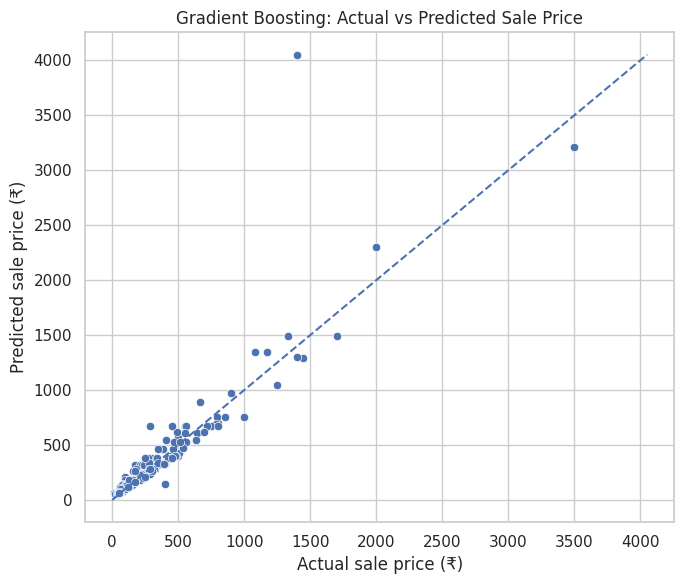

Saved test predictions to: /content/bigbasket_price_predictions.csv


In [ ]:
# Compare actual and predicted prices for test examples.
prediction_results = pd.DataFrame({
    "Actual Sale Price": y_test.to_numpy(),
    "Predicted Sale Price": y_pred
})
prediction_results["Absolute Error"] = (
    prediction_results["Actual Sale Price"] - prediction_results["Predicted Sale Price"]
).abs()
display(prediction_results.head(15).round(2))

plt.figure(figsize=(7, 6))
sns.scatterplot(
    x=prediction_results["Actual Sale Price"],
    y=prediction_results["Predicted Sale Price"]
)
max_price = max(
    prediction_results["Actual Sale Price"].max(),
    prediction_results["Predicted Sale Price"].max()
)
plt.plot([0, max_price], [0, max_price], linestyle="--")
plt.title("Gradient Boosting: Actual vs Predicted Sale Price")
plt.xlabel("Actual sale price (₹)")
plt.ylabel("Predicted sale price (₹)")
plt.tight_layout()
plt.show()

# Save test predictions for the project report.
prediction_file = Path("bigbasket_price_predictions.csv")
prediction_results.to_csv(prediction_file, index=False)
print("Saved test predictions to:", prediction_file.resolve())


,Feature,Importance
0,numeric__MRP,0.9842
513,categorical__Brand_Police,0.0024
371,categorical__Brand_Lexton,0.0022
773,categorical__Product_Type_Eau De Toilette,0.0021
13,categorical__Subcategory_Appliances & Electricals,0.0016
294,categorical__Brand_Guess,0.0013
464,categorical__Brand_Nova,0.0011
51,categorical__Subcategory_Fragrances & Deos,0.0009
908,categorical__Product_Type_Pressure Cookers,0.0007
117,categorical__Brand_Anna sui,0.0006


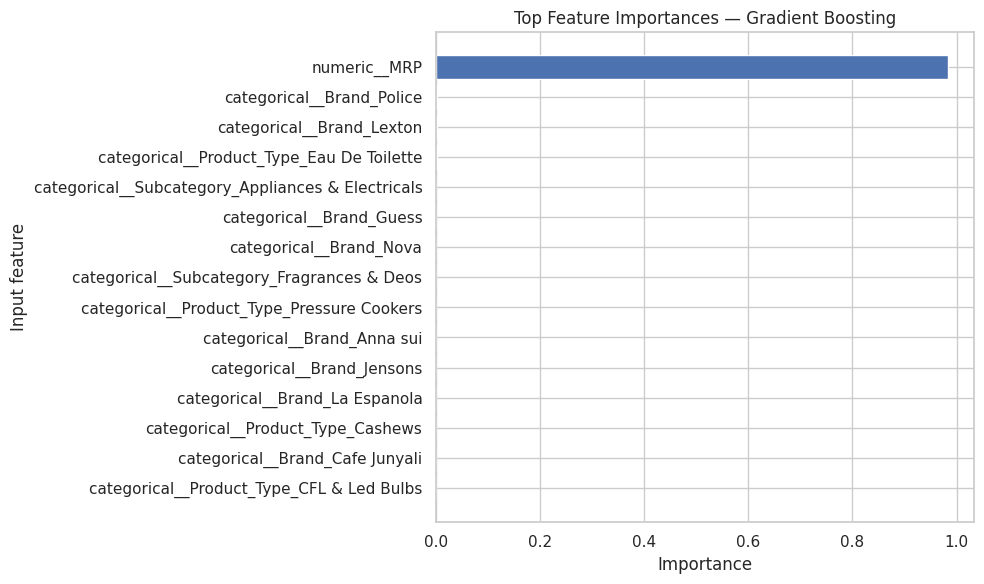

Saved feature importance to: bigbasket_model_feature_importance.csv


In [ ]:
# Feature importance helps explain which input features the model relied on most.
fitted_preprocessor = gradient_boosting_model.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
importances = gradient_boosting_model.named_steps["regressor"].feature_importances_

feature_importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .head(15)
)

display(feature_importance.round(4))

plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Feature"][::-1], feature_importance["Importance"][::-1])
plt.title("Top Feature Importances — Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Input feature")
plt.tight_layout()
plt.show()

feature_importance.to_csv("bigbasket_model_feature_importance.csv", index=False)
print("Saved feature importance to: bigbasket_model_feature_importance.csv")


In [ ]:
# Example: predict the sale price for a hypothetical product.
# Replace these values with a product's real attributes when available.
new_product = pd.DataFrame([{
    "MRP": 250.0,
    "Category": "Cleaning & Household",
    "Subcategory": "Storage & Accessories",
    "Brand": "Nakoda",
    "Product_Type": "Laundry Storage Baskets"
}])

predicted_price = gradient_boosting_model.predict(new_product[feature_columns])[0]
print("Example product details:")
display(new_product)
print(f"Predicted sale price: ₹{predicted_price:.2f}")
print("Note: This is a model estimate, not a guaranteed or live BigBasket price.")


Example product details:


,MRP,Category,Subcategory,Brand,Product_Type
0,250.0,Cleaning & Household,Storage & Accessories,Nakoda,Laundry Storage Baskets


Predicted sale price: ₹210.44
Note: This is a model estimate, not a guaranteed or live BigBasket price.


## 12. Conclusion

The notebook explores the supplied BigBasket product sample through data cleaning, descriptive statistics, outlier detection, category/brand analysis, and visualizations. It also trains a Gradient Boosting regression model to estimate product sale prices using MRP and product-category information. Model performance is assessed using MAE, RMSE, and R² on a held-out test set. Report the measured scores from the executed notebook and note that the dataset is a sample and BigBasket live scraping returned HTTP 403; predictions are estimates, not current prices.


In [ ]:

pt = "Adult Diapers"

check = df[df["Product_Type"].str.strip() == pt][
    ["Product", "Product_Type", "Category", "Subcategory", "Brand"]
]

print("Matching rows:", len(check))
display(check.head(20))

print("\nCategories for this Product Type:")
display(check["Category"].value_counts())

print("\nSubcategories for this Product Type:")
display(check["Subcategory"].value_counts())


Matching rows: 3


,Product,Product_Type,Category,Subcategory,Brand
448,Kare in Adult Diapers Pants Large,Adult Diapers,Beauty & Hygiene,Health & Medicine,Kare In
483,Extra Absorb Adult Pant Style Diapers - XL,Adult Diapers,Beauty & Hygiene,Health & Medicine,Lifree
1061,Easy Adult Diaper - X-Large,Adult Diapers,Beauty & Hygiene,Health & Medicine,Friends



Categories for this Product Type:


,count
Category,
Beauty & Hygiene,3



Subcategories for this Product Type:


,count
Subcategory,
Health & Medicine,3


## 12. Gradio prediction interface
Run the next cells in Google Colab to open an interactive form. Enter/select product details and click **Predict Sale Price**. The model estimates `Price` from the selected features; it does not fetch live BigBasket prices.


In [ ]:
%pip -q install gradio


In [ ]:

import gradio as gr
import pandas as pd

df = pd.read_csv("/content/bigbasket_cleaned (1).csv")

# Clean required columns
for col in ["Product", "Product_Type", "Brand"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df = df.dropna(subset=["Price"])
df = df[df["Product"] != ""]

product_types = sorted(x for x in df["Product_Type"].unique() if x)

def update_products(product_type):
    data = df.copy()

    if product_type:
        data = data[data["Product_Type"] == product_type]

    products = sorted(data["Product"].unique().tolist())
    return gr.Dropdown(choices=products, value=None)

def show_details(product_type, product):
    data = df.copy()

    if product_type:
        data = data[data["Product_Type"] == product_type]

    if product:
        data = data[data["Product"] == product]

    if data.empty:
        return "—", "—"

    row = data.iloc[0]
    brand = row["Brand"] if row["Brand"] else "Not available"
    price = f"₹{row['Price']:,.2f}"

    return brand, price

css = """
.gradio-container {
    max-width: 950px !important;
    margin: auto !important;
}
#header {
    background: linear-gradient(120deg, #08783e, #20a464);
    color: white;
    padding: 24px;
    border-radius: 16px;
    margin-bottom: 18px;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="emerald"
    ),
    css=css,
    title="BigBasket Product Finder"
) as demo:

    gr.HTML("""
    <div id="header">
        <h1>🛒 BigBasket Product Finder</h1>
        <p>Choose a product type to explore products, brands and prices.</p>
    </div>
    """)

    with gr.Group():
        gr.Markdown("### Select Your Product")

        product_type = gr.Dropdown(
            choices=product_types,
            label="Product Type",
            value=None
        )

        product = gr.Dropdown(
            choices=[],
            label="Product Name",
            value=None
        )

        find_btn = gr.Button(
            "View Product Details",
            variant="primary"
        )

    gr.Markdown("### Product Information")

    with gr.Row():
        brand_output = gr.Textbox(
            label="Product Brand",
            interactive=False
        )
        price_output = gr.Textbox(
            label="Product Price",
            interactive=False
        )

    product_type.change(
        fn=update_products,
        inputs=product_type,
        outputs=product
    )

    find_btn.click(
        fn=show_details,
        inputs=[product_type, product],
        outputs=[brand_output, price_output]
    )

    gr.Markdown(
        "*Prices and product details are taken from the loaded dataset.*"
    )

demo.launch(share=True)


/tmp/ipykernel_2384/744707348.py:57: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://414b95371e44d25fca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
